<a href="https://colab.research.google.com/github/vivekcode12345/phishguard-ml/blob/main/notebooks/project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os
base = '/content/drive/MyDrive/phishing-project'
os.makedirs(base + '/data', exist_ok=True)
print(os.listdir(base))

['data']


In [ ]:
import pandas as pd
import requests

url = "http://data.phishtank.com/data/online-valid.csv"
headers = {"User-Agent": "phishtank/your-college-project"}

r = requests.get(url, headers=headers, timeout=120)
print("Status:", r.status_code)

if r.status_code == 200:
    path = base + "/data/phishtank_raw.csv"
    with open(path, "wb") as f:
        f.write(r.content)
    df = pd.read_csv(path)
    print(df.shape)
    print(df.columns.tolist())
    print(df[["url", "submission_time"]].head())

Status: 200
(53171, 8)
['phish_id', 'url', 'phish_detail_url', 'submission_time', 'verified', 'verification_time', 'online', 'target']
                                              url            submission_time
0  https://poonkiewaters.com/ipko/pages/login.php  2026-10-30T15:52:22+00:00
1                        http://tf-app.vercel.app  2026-10-30T15:25:13+00:00
2                      https://tf-app.vercel.app/  2026-10-30T15:25:13+00:00
3     https://faciliteagora.vercel.app/index.html  2026-10-30T14:17:20+00:00
4             https://farm-rio-outlet.vercel.app/  2026-10-30T13:28:17+00:00


In [ ]:
df["submission_time"] = pd.to_datetime(df["submission_time"])

print("Earliest:", df["submission_time"].min())
print("Latest:  ", df["submission_time"].max())
print("Unique URLs:", df["url"].nunique(), "/", len(df))

print(df["submission_time"].dt.to_period("M").value_counts().sort_index().tail(24))

Earliest: 2011-02-18 10:50:32+00:00
Latest:   2026-10-30 15:52:22+00:00
Unique URLs: 53169 / 53171
submission_time
2024-11    1452
2024-12     896
2025-01     599
2025-02     424
2025-03     526
2025-04     537
2025-05     548
2025-06     405
2025-07     926
2025-08     996
2025-09     882
2025-10     799
2025-11     729
2025-12     470
2026-01    2278
2026-02    3468
2026-03     939
2026-04    1222
2026-05    2109
2026-06    2414
2026-07    2614
2026-08    2130
2026-09    1380
2026-10    2479
Freq: M, Name: count, dtype: int64


/tmp/ipykernel_3200/1751158847.py:7: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  print(df["submission_time"].dt.to_period("M").value_counts().sort_index().tail(24))


In [ ]:
phish = df[["url", "submission_time"]].copy()
phish["submission_time"] = phish["submission_time"].dt.tz_convert(None)

phish = phish[phish["submission_time"] >= "2024-11-01"]
phish = phish.drop_duplicates("url")
phish["label"] = 1
phish["source"] = "phishtank"

phish.to_csv(base + "/data/phish_clean.csv", index=False)
print(phish.shape)
print(phish["submission_time"].min(), "to", phish["submission_time"].max())
phish.head()

(31222, 4)
2024-11-01 06:35:59 to 2026-10-30 15:52:22


,url,submission_time,label,source
0,https://poonkiewaters.com/ipko/pages/login.php,2026-10-30 15:52:22,1,phishtank
1,http://tf-app.vercel.app,2026-10-30 15:25:13,1,phishtank
2,https://tf-app.vercel.app/,2026-10-30 15:25:13,1,phishtank
3,https://faciliteagora.vercel.app/index.html,2026-10-30 14:17:20,1,phishtank
4,https://farm-rio-outlet.vercel.app/,2026-10-30 13:28:17,1,phishtank


In [ ]:
import zipfile, io

r = requests.get("https://tranco-list.eu/top-1m.csv.zip", timeout=120)
print("Status:", r.status_code)

z = zipfile.ZipFile(io.BytesIO(r.content))
tranco = pd.read_csv(z.open("top-1m.csv"), names=["rank", "domain"])

tranco.to_csv(base + "/data/tranco_raw.csv", index=False)
print(tranco.shape)
tranco.head(10)

Status: 200
(1000000, 2)


,rank,domain
0,1,google.com
1,2,cloudflare.com
2,3,amazonaws.com
3,4,ezviz7.com
4,5,facebook.com
5,6,fbcdn.net
6,7,gstatic.com
7,8,googleapis.com
8,9,akamai.net
9,10,microsoft.com


In [ ]:
import json, time, random, requests
import pandas as pd

# 1. Server check
try:
    info = requests.get("https://index.commoncrawl.org/collinfo.json", timeout=30).json()
    cdx_api = info[0]["cdx-api"]
    print("Server OK, using:", info[0]["id"])
    server_ok = True
except Exception as e:
    print("Server abhi bhi nahi chal raha:", type(e).__name__)
    server_ok = False

# 2. Pilot (sirf server OK ho to)
if server_ok:
    def cc_urls(domain, limit=10, retries=2):
        params = {
            "url": domain,
            "matchType": "domain",
            "output": "json",
            "fl": "url",
            "filter": ["=status:200", "=mime:text/html"],
            "collapse": "urlkey",
            "limit": limit,
        }
        for attempt in range(retries + 1):
            try:
                r = requests.get(cdx_api, params=params, timeout=60)
                if r.status_code == 200:
                    text = r.text.strip()
                    return [json.loads(l)["url"] for l in text.split("\n") if l]
            except requests.exceptions.RequestException:
                pass
            time.sleep(3)
        return None

    random.seed(42)
    pool = tranco[tranco["rank"] <= 20000]["domain"].tolist()
    sample = random.sample(pool, 60)

    rows, failed, streak = [], [], 0
    for i, d in enumerate(sample):
        urls = cc_urls(d)
        if urls is None:
            failed.append(d)
            streak += 1
            if streak >= 5:
                print("Lagatar 5 domains fail hue, ruk raha hoon.")
                break
        else:
            streak = 0
            rows += [(u, d) for u in urls]
        time.sleep(1)
        if (i + 1) % 10 == 0:
            print(f"{i+1}/60 done")

    legit = pd.DataFrame(rows, columns=["url", "domain"])
    legit.to_csv(base + "/data/legit_pilot.csv", index=False)

    print("Domains failed:", len(failed), "/ 60")
    print("Total URLs:", len(legit))
    print("With paths:", (legit["url"].str.count("/") > 3).sum())
    print(legit.sample(min(10, len(legit)), random_state=1)["url"].to_string())

Server OK, using: CC-MAIN-2026-43
Lagatar 5 domains fail hue, ruk raha hoon.
Domains failed: 5 / 60
Total URLs: 0
With paths: 0
Series([], )


In [ ]:
import requests, json, time

def test(label, api, params):
    try:
        r = requests.get(api, params=params, timeout=60)
        print(f"{label} -> HTTP {r.status_code} | {r.text[:120]!r}")
    except Exception as e:
        print(f"{label} -> {type(e).__name__}")

# Wo domains jo pehle chale the (wikipedia, github) + ek random
for d in ["wikipedia.org", "github.com", "bbc.com"]:
    # Light query: domain/* , bina matchType ke
    test(f"{d} (light, latest crawl)", cdx_api,
         {"url": f"{d}/*", "output": "json", "fl": "url", "limit": 5})
    time.sleep(2)

# Ek purana crawl index try karo
old_api = info[1]["cdx-api"]
print("Older crawl:", info[1]["id"])
test("wikipedia.org (older crawl)", old_api,
     {"url": "wikipedia.org/*", "output": "json", "fl": "url", "limit": 5})

wikipedia.org (light, latest crawl) -> ConnectionError
github.com (light, latest crawl) -> ConnectionError
bbc.com (light, latest crawl) -> ConnectionError
Older crawl: CC-MAIN-2026-39
wikipedia.org (older crawl) -> ConnectionError


In [ ]:
import requests, random
from urllib.parse import urljoin, urlparse
from bs4 import BeautifulSoup
from concurrent.futures import ThreadPoolExecutor
import pandas as pd

HEADERS = {"User-Agent": "Mozilla/5.0 (college research project)"}
SKIP_EXT = (".jpg", ".jpeg", ".png", ".gif", ".svg", ".css", ".js", ".pdf",
            ".zip", ".ico", ".mp4", ".xml", ".woff", ".woff2")

def get_links(domain, per_domain=10):
    try:
        r = requests.get(f"https://{domain}", headers=HEADERS, timeout=10)
        if r.status_code != 200 or "text/html" not in r.headers.get("Content-Type", ""):
            return []
        soup = BeautifulSoup(r.text, "html.parser")
        out = set()
        for a in soup.find_all("a", href=True):
            u = urljoin(r.url, a["href"]).split("#")[0]
            p = urlparse(u)
            if p.scheme not in ("http", "https"):
                continue
            host = p.netloc.lower()
            if not (host == domain or host.endswith("." + domain)):
                continue
            if len(p.path) <= 1 and not p.query:
                continue
            if p.path.lower().endswith(SKIP_EXT):
                continue
            out.add(u)
        out = list(out)
        random.shuffle(out)
        return out[:per_domain]
    except Exception:
        return []

random.seed(42)
pool = tranco[tranco["rank"] <= 20000]["domain"].tolist()
sample = random.sample(pool, 60)

with ThreadPoolExecutor(max_workers=20) as ex:
    results = list(ex.map(get_links, sample))

rows = [(u, d) for d, urls in zip(sample, results) for u in urls]
legit = pd.DataFrame(rows, columns=["url", "domain"])
legit.to_csv(base + "/data/legit_pilot.csv", index=False)

print("Domains that gave links:", sum(1 for r in results if r), "/ 60")
print("Total URLs:", len(legit))
print(legit.sample(min(10, len(legit)), random_state=1)["url"].to_string())

Domains that gave links: 32 / 60
Total URLs: 300
189    https://www.aok.de/pk/news/grippeimpfung-wer-s...
123                https://dstillery.com/audience-studio
185          https://www.aok.de/pk/magazin/wohlbefinden/
213    https://www.ccc.de/club/chaostreffs/chaostreff...
106    https://www.nordea.com/en/about-us/corporate-g...
127          https://media.buyee.jp/pr/about_auction/en/
176                                https://maps.me/maps/
73                      https://material.security/events
275          https://avtub.wiki/category/jav-uncensored/
242            https://www.socialmediatoday.com/contact/


In [ ]:
"""
Legitimate URL collection.

Samples domains from the Tranco top-100k list, fetches each homepage, and
extracts same-site links that contain a path or query string. Results are
saved in chunks to Google Drive so the job can resume after a disconnect.
"""

import os
import random
import time
from concurrent.futures import ThreadPoolExecutor
from urllib.parse import urljoin, urlparse

import pandas as pd
import requests
from bs4 import BeautifulSoup

# Configuration
HEADERS = {"User-Agent": "Mozilla/5.0 (academic research project)"}
SKIP_EXTENSIONS = (".jpg", ".jpeg", ".png", ".gif", ".svg", ".css", ".js", ".pdf",
                   ".zip", ".ico", ".mp4", ".xml", ".woff", ".woff2")
URLS_PER_DOMAIN = 10
N_DOMAINS = 6000
CHUNK_SIZE = 500
MAX_WORKERS = 40
SEED = 7


def get_links(domain, per_domain=URLS_PER_DOMAIN):
    """Return up to `per_domain` same-site URLs (with a path or query) from a domain's homepage."""
    try:
        resp = requests.get(f"https://{domain}", headers=HEADERS, timeout=10)
        if resp.status_code != 200 or "text/html" not in resp.headers.get("Content-Type", ""):
            return []

        soup = BeautifulSoup(resp.text, "html.parser")
        links = set()
        for anchor in soup.find_all("a", href=True):
            url = urljoin(resp.url, anchor["href"]).split("#")[0]
            parsed = urlparse(url)

            if parsed.scheme not in ("http", "https"):
                continue
            host = parsed.netloc.lower()
            if not (host == domain or host.endswith("." + domain)):
                continue  # keep same-site links only
            if len(parsed.path) <= 1 and not parsed.query:
                continue  # skip bare homepages
            if parsed.path.lower().endswith(SKIP_EXTENSIONS):
                continue  # skip static assets

            links.add(url)

        links = list(links)
        random.shuffle(links)
        return links[:per_domain]
    except Exception:
        return []  # unreachable, blocked, or malformed response


# Domain sampling
random.seed(SEED)
pool = tranco[tranco["rank"] <= 100_000]
sample = pool.sample(N_DOMAINS, random_state=SEED)
domains = sample["domain"].tolist()
rank_of = dict(zip(sample["domain"], sample["rank"]))

chunk_dir = os.path.join(base, "data", "legit_chunks")
os.makedirs(chunk_dir, exist_ok=True)

# Chunked collection with checkpointing
n_chunks = len(domains) // CHUNK_SIZE
start_time = time.time()

for chunk_idx in range(n_chunks):
    chunk_path = os.path.join(chunk_dir, f"chunk_{chunk_idx:02d}.csv")
    if os.path.exists(chunk_path):
        continue  # checkpoint exists, skip this chunk

    batch = domains[chunk_idx * CHUNK_SIZE:(chunk_idx + 1) * CHUNK_SIZE]
    with ThreadPoolExecutor(max_workers=MAX_WORKERS) as executor:
        results = list(executor.map(get_links, batch))

    rows = [(url, dom, rank_of[dom]) for dom, urls in zip(batch, results) for url in urls]
    pd.DataFrame(rows, columns=["url", "domain", "rank"]).to_csv(chunk_path, index=False)

    elapsed = int(time.time() - start_time)
    print(f"Chunk {chunk_idx + 1}/{n_chunks} complete | {len(rows)} URLs | {elapsed}s elapsed")

print("Collection complete.")

Chunk 4/12 complete | 2125 URLs | 45s elapsed
Chunk 5/12 complete | 2139 URLs | 148s elapsed
Chunk 6/12 complete | 2250 URLs | 183s elapsed
Chunk 7/12 complete | 2207 URLs | 216s elapsed
Chunk 8/12 complete | 1915 URLs | 248s elapsed
Chunk 9/12 complete | 2225 URLs | 467s elapsed
Chunk 10/12 complete | 2346 URLs | 511s elapsed
Chunk 11/12 complete | 2202 URLs | 630s elapsed
Chunk 12/12 complete | 2018 URLs | 666s elapsed
Collection complete.


In [ ]:
!pip install -q tldextract

import glob
import pandas as pd
import tldextract

# Load legitimate URL chunks and phishing data
chunk_files = sorted(glob.glob(base + "/data/legit_chunks/chunk_*.csv"))
print("Legitimate chunk files found:", len(chunk_files))

legit = pd.concat([pd.read_csv(f) for f in chunk_files], ignore_index=True)
phish = pd.read_csv(base + "/data/phish_clean.csv", parse_dates=["submission_time"])
print(f"Raw counts -> legitimate: {len(legit)}, phishing: {len(phish)}")

# Clean legitimate data
legit["url"] = legit["url"].str.strip()
legit = legit.drop_duplicates("url").reset_index(drop=True)
legit["label"] = 0
legit["source"] = "tranco_homepage_links"
legit["submission_time"] = pd.NaT  # no reliable timestamp for legitimate URLs

# Clean phishing data
phish["url"] = phish["url"].str.strip()
phish = phish.drop_duplicates("url").reset_index(drop=True)
phish["rank"] = pd.NA

# Combine
cols = ["url", "label", "source", "submission_time", "rank"]
df_all = pd.concat([phish[cols], legit[cols]], ignore_index=True)
df_all = df_all.drop_duplicates("url").reset_index(drop=True)

# Registered domain (needed later for domain-disjoint splits)
def registered_domain(url):
    ext = tldextract.extract(url)
    return f"{ext.domain}.{ext.suffix}" if ext.suffix else ext.domain

df_all["domain"] = df_all["url"].map(registered_domain)

# Save
df_all.to_csv(base + "/data/dataset_v1.csv", index=False)

# Summary
print("\nClass counts:")
print(df_all["label"].value_counts())
print("\nUnique registered domains per class:")
print(df_all.groupby("label")["domain"].nunique())

overlap = set(df_all[df_all.label == 1]["domain"]) & set(df_all[df_all.label == 0]["domain"])
print("\nDomains present in both classes:", len(overlap))
print(sorted(overlap)[:15])

df_all["url_len"] = df_all["url"].str.len()
df_all["n_slashes"] = df_all["url"].str.count("/")
print("\nURL length and slash count by class:")
print(df_all.groupby("label")[["url_len", "n_slashes"]].describe().T.loc[
    [("url_len", "mean"), ("url_len", "50%"), ("n_slashes", "mean"), ("n_slashes", "50%")]
])

Legitimate chunk files found: 12
Raw counts -> legitimate: 25938, phishing: 31222

Class counts:
label
1    31222
0    25937
Name: count, dtype: int64

Unique registered domains per class:
label
0    2788
1    7963
Name: domain, dtype: int64

Domains present in both classes: 7
['benefitsaccess-center.com', 'framer.com', 'google.com.hk', 'link.me', 'ramp.com', 'tr.ee', 'yam.com']

URL length and slash count by class:
label                   0          1
url_len   mean  54.618229  50.958235
          50%   46.000000  37.000000
n_slashes mean   4.292632   3.408686
          50%    4.000000   3.000000


In [ ]:
import pandas as pd

df_all = pd.read_csv(base + "/data/dataset_v1.csv", parse_dates=["submission_time"])

# Domains that appear in both classes (e.g. free hosting or URL shorteners)
dom_by_class = df_all.groupby("domain")["label"].nunique()
overlap = set(dom_by_class[dom_by_class > 1].index)
print("Overlapping domains removed:", sorted(overlap))

df_final = df_all[~df_all["domain"].isin(overlap)].reset_index(drop=True)
df_final.to_csv(base + "/data/dataset_final_v1.csv", index=False)

print("\nFinal shape:", df_final.shape)
print(df_final["label"].value_counts())
print("\nUnique domains per class:")
print(df_final.groupby("label")["domain"].nunique())
print("\nPhishing date range:",
      df_final[df_final.label == 1]["submission_time"].min(), "to",
      df_final[df_final.label == 1]["submission_time"].max())


Overlapping domains removed: ['benefitsaccess-center.com', 'framer.com', 'google.com.hk', 'link.me', 'ramp.com', 'tr.ee', 'yam.com']

Final shape: (57052, 6)
label
1    31178
0    25874
Name: count, dtype: int64

Unique domains per class:
label
0    2781
1    7956
Name: domain, dtype: int64

Phishing date range: 2024-11-01 06:35:59 to 2026-10-30 15:52:22


Mounted at /content/drive
Mean feature values by class (0 = legitimate, 1 = phishing):
label                 0       1
url_len          54.641  50.973
path_len         28.982  12.671
n_dots            1.828   1.892
n_hyphens         2.080   0.939
n_digits          2.107   5.428
digit_ratio       0.028   0.076
n_slashes         4.294   3.409
has_query         0.075   0.135
is_https          0.992   0.913
has_ip_host       0.000   0.000
subdomain_depth   0.586   0.705


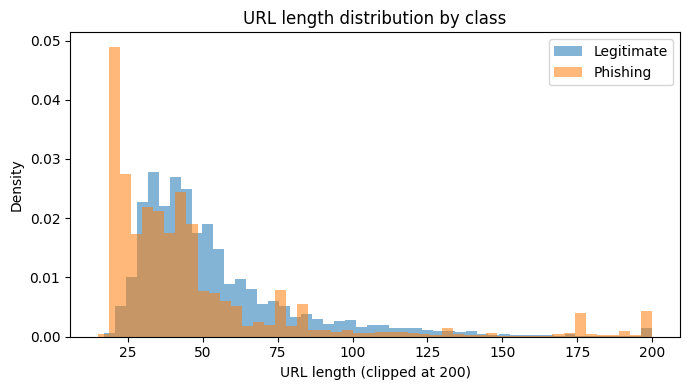


Top TLDs by class (share of class):

Legitimate:
tld
com       46.1
org        5.4
ru         3.8
de         3.3
net        3.2
edu        1.6
io         1.3
it         1.3
fr         1.2
com.br     1.2
Name: proportion, dtype: float64

Phishing:
tld
com    37.0
de      8.4
to      6.0
app     5.8
me      5.8
dev     3.7
io      3.3
ly      2.4
co      2.0
top     1.5
Name: proportion, dtype: float64

Single-feature shortcut check (domain-disjoint split, test AUC):
       single_feature  test_auc
            n_slashes     0.778
             path_len     0.760
tld (top 50, one-hot)     0.652
             n_digits     0.632
          digit_ratio     0.625
              url_len     0.604
      subdomain_depth     0.567
               n_dots     0.564
            n_hyphens     0.541
            has_query     0.534
             is_https     0.523
          has_ip_host     0.500


In [2]:
# Phase 2: Exploratory Data Analysis and shortcut-feature check

import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
!pip install -q tldextract
import tldextract
from urllib.parse import urlparse
from sklearn.model_selection import GroupShuffleSplit
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import roc_auc_score

# Re-mount Drive if this is a fresh session
try:
    base
except NameError:
    from google.colab import drive
    drive.mount("/content/drive")
    base = "/content/drive/MyDrive/phishing-project"

df = pd.read_csv(base + "/data/dataset_final_v1.csv", parse_dates=["submission_time"])
os.makedirs(base + "/figures", exist_ok=True)

# Basic lexical features
IP_PATTERN = re.compile(r"^(\d{1,3}\.){3}\d{1,3}$")

def basic_features(url):
    parsed = urlparse(url if "://" in url else "http://" + url)
    host = parsed.netloc.lower()
    ext = tldextract.extract(url)
    return {
        "url_len": len(url),
        "path_len": len(parsed.path),
        "n_dots": url.count("."),
        "n_hyphens": url.count("-"),
        "n_digits": sum(c.isdigit() for c in url),
        "n_slashes": url.count("/"),
        "has_query": int("?" in url),
        "has_at": int("@" in url),
        "is_https": int(parsed.scheme == "https"),
        "has_ip_host": int(bool(IP_PATTERN.match(host.split(":")[0]))),
        "subdomain_depth": len([s for s in ext.subdomain.split(".") if s]),
        "tld": ext.suffix or "none",
    }

feats = pd.DataFrame([basic_features(u) for u in df["url"]])
data = pd.concat([df[["url", "label", "domain"]], feats], axis=1)
data["digit_ratio"] = data["n_digits"] / data["url_len"]

# 1. Per-class summary
num_cols = ["url_len", "path_len", "n_dots", "n_hyphens", "n_digits",
            "digit_ratio", "n_slashes", "has_query", "is_https",
            "has_ip_host", "subdomain_depth"]
print("Mean feature values by class (0 = legitimate, 1 = phishing):")
print(data.groupby("label")[num_cols].mean().T.round(3))

# 2. URL length distribution
fig, ax = plt.subplots(figsize=(7, 4))
for lbl, name in [(0, "Legitimate"), (1, "Phishing")]:
    ax.hist(data.loc[data.label == lbl, "url_len"].clip(upper=200),
            bins=50, alpha=0.55, density=True, label=name)
ax.set_xlabel("URL length (clipped at 200)")
ax.set_ylabel("Density")
ax.set_title("URL length distribution by class")
ax.legend()
fig.tight_layout()
fig.savefig(base + "/figures/eda_url_length.png", dpi=200)
plt.show()

# 3. TLD distribution
print("\nTop TLDs by class (share of class):")
for lbl, name in [(0, "Legitimate"), (1, "Phishing")]:
    print(f"\n{name}:")
    print((data[data.label == lbl]["tld"].value_counts(normalize=True).head(10) * 100).round(1))

# 4. Single-feature shortcut check (domain-disjoint split)
# Each model sees only ONE feature. A high AUC means that feature alone
# separates the classes, which indicates dataset bias rather than phishing signal.
splitter = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=42)
train_idx, test_idx = next(splitter.split(data, data["label"], groups=data["domain"]))
y_train, y_test = data.loc[train_idx, "label"], data.loc[test_idx, "label"]

results = []
for col in num_cols:
    clf = DecisionTreeClassifier(max_depth=3, random_state=42)
    clf.fit(data.loc[train_idx, [col]], y_train)
    auc = roc_auc_score(y_test, clf.predict_proba(data.loc[test_idx, [col]])[:, 1])
    results.append((col, auc))

# TLD as a categorical feature (top 50 TLDs, one-hot encoded)
top_tlds = data.loc[train_idx, "tld"].value_counts().head(50).index
tld_onehot = pd.get_dummies(data["tld"].where(data["tld"].isin(top_tlds), "other"))
clf = DecisionTreeClassifier(max_depth=5, random_state=42)
clf.fit(tld_onehot.loc[train_idx], y_train)
results.append(("tld (top 50, one-hot)",
                roc_auc_score(y_test, clf.predict_proba(tld_onehot.loc[test_idx])[:, 1])))

shortcut = pd.DataFrame(results, columns=["single_feature", "test_auc"]).sort_values("test_auc", ascending=False)
print("\nSingle-feature shortcut check (domain-disjoint split, test AUC):")
print(shortcut.to_string(index=False, float_format=lambda x: f"{x:.3f}"))

In [3]:
# Phase 2b: Correct the bare-domain sampling bias

import random

df = pd.read_csv(base + "/data/dataset_final_v1.csv", parse_dates=["submission_time"])
tranco = pd.read_csv(base + "/data/tranco_raw.csv")


def is_bare(url):
    """True if the URL has no path (beyond '/') and no query string."""
    p = urlparse(url if "://" in url else "http://" + url)
    return int(p.path in ("", "/") and not p.query)


df["is_bare"] = df["url"].map(is_bare)
print("Share of domain-only URLs, BEFORE correction:")
print(df.groupby("label")["is_bare"].mean().round(3))

# Target: match the phishing class's share of domain-only URLs
p = df.loc[df.label == 1, "is_bare"].mean()
slash_rate = df.loc[(df.label == 1) & (df.is_bare == 1), "url"].str.endswith("/").mean()
L = (df.label == 0).sum()
b = df.loc[df.label == 0, "is_bare"].sum()
n_add = int((p * L - b) / (1 - p))

# Candidate domains: Tranco top-100k, not already used by either class
used = set(df["domain"])
cand = tranco[(tranco["rank"] <= 100_000) & (~tranco["domain"].isin(used))]
n_add = min(n_add, len(cand))
new = cand.sample(n_add, random_state=11).copy()

rng = random.Random(11)
new["url"] = [f"https://{d}/" if rng.random() < slash_rate else f"https://{d}"
              for d in new["domain"]]
new["label"] = 0
new["source"] = "tranco_homepage"
new["submission_time"] = pd.NaT

df2 = pd.concat([df.drop(columns="is_bare"),
                 new[["url", "label", "source", "submission_time", "rank", "domain"]]],
                ignore_index=True).drop_duplicates("url").reset_index(drop=True)
df2.to_csv(base + "/data/dataset_final_v2.csv", index=False)

df2["is_bare"] = df2["url"].map(is_bare)
print(f"\nAdded {n_add} homepage URLs from {n_add} new domains")
print("Share of domain-only URLs, AFTER correction:")
print(df2.groupby("label")["is_bare"].mean().round(3))
print("\nClass counts:")
print(df2["label"].value_counts())
print("Unique domains per class:")
print(df2.groupby("label")["domain"].nunique())

# Re-run the single-feature shortcut check on the corrected dataset
feats2 = pd.DataFrame([basic_features(u) for u in df2["url"]])
data2 = pd.concat([df2[["label", "domain"]], feats2], axis=1)
data2["digit_ratio"] = data2["n_digits"] / (df2["url"].str.len())

tr, te = next(GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=42)
              .split(data2, data2["label"], groups=data2["domain"]))
rows = []
for col in num_cols:
    clf = DecisionTreeClassifier(max_depth=3, random_state=42)
    clf.fit(data2.loc[tr, [col]], data2.loc[tr, "label"])
    auc = roc_auc_score(data2.loc[te, "label"], clf.predict_proba(data2.loc[te, [col]])[:, 1])
    rows.append((col, auc))

print("\nSingle-feature shortcut check AFTER correction (test AUC):")
print(pd.DataFrame(rows, columns=["single_feature", "test_auc"])
      .sort_values("test_auc", ascending=False).to_string(index=False, float_format=lambda x: f"{x:.3f}"))

Share of domain-only URLs, BEFORE correction:
label
0    0.00
1    0.33
Name: is_bare, dtype: float64

Added 12735 homepage URLs from 12735 new domains
Share of domain-only URLs, AFTER correction:
label
0    0.33
1    0.33
Name: is_bare, dtype: float64

Class counts:
label
0    38609
1    31178
Name: count, dtype: int64
Unique domains per class:
label
0    15516
1     7956
Name: domain, dtype: int64

Single-feature shortcut check AFTER correction (test AUC):
 single_feature  test_auc
       path_len     0.745
      n_slashes     0.693
subdomain_depth     0.640
      n_hyphens     0.635
    digit_ratio     0.629
       n_digits     0.623
         n_dots     0.622
       is_https     0.536
      has_query     0.520
    has_ip_host     0.500
        url_len     0.486


In [4]:
# Phase 3: Train / validation / test splits

import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

df = pd.read_csv(base + "/data/dataset_final_v2.csv", parse_dates=["submission_time"])
SEED = 42
RATIOS = (0.70, 0.15, 0.15)
NAMES = ["train", "val", "test"]
rng = np.random.default_rng(SEED)


def assign_groups(sizes, order):
    """Assign whole groups (domains) to splits following `order`, filling by cumulative row count."""
    total = sizes.sum()
    b1, b2 = RATIOS[0] * total, (RATIOS[0] + RATIOS[1]) * total
    out, cum = {}, 0
    for g in order:
        out[g] = NAMES[0] if cum < b1 else NAMES[1] if cum < b2 else NAMES[2]
        cum += sizes[g]
    return out


# 1. Random split (reference only)
idx = np.arange(len(df))
tr, tmp = train_test_split(idx, test_size=0.30, stratify=df["label"], random_state=SEED)
va, te = train_test_split(tmp, test_size=0.50, stratify=df.loc[tmp, "label"], random_state=SEED)
df["split_random"] = "train"
df.loc[va, "split_random"] = "val"
df.loc[te, "split_random"] = "test"

# 2. Domain-disjoint split (per class, whole domains)
df["split_domain"] = ""
for lbl in (0, 1):
    sub = df[df.label == lbl]
    sizes = sub.groupby("domain").size()
    order = rng.permutation(sizes.index.to_numpy())
    df.loc[sub.index, "split_domain"] = sub["domain"].map(assign_groups(sizes, order))

# 3. Chronological split (domain-disjoint as well)
df["split_chrono"] = ""
ph = df[df.label == 1]
first_seen = ph.groupby("domain")["submission_time"].min().sort_values()
sizes = ph.groupby("domain").size()
df.loc[ph.index, "split_chrono"] = ph["domain"].map(assign_groups(sizes, first_seen.index))

lg = df[df.label == 0]
sizes = lg.groupby("domain").size()
order = rng.permutation(sizes.index.to_numpy())
df.loc[lg.index, "split_chrono"] = lg["domain"].map(assign_groups(sizes, order))

# Summary and leakage checks
for col in ["split_random", "split_domain", "split_chrono"]:
    print(f"\n{col}: rows per split and class")
    print(pd.crosstab(df[col], df["label"]).reindex(NAMES))

print("\nPhishing date range per chronological split:")
print(df[df.label == 1].groupby("split_chrono")["submission_time"].agg(["min", "max"]).reindex(NAMES))

print("\nDomain overlap between splits (must be 0):")
for col in ["split_domain", "split_chrono"]:
    d = {s: set(df.loc[df[col] == s, "domain"]) for s in NAMES}
    print(f"{col}: train/val={len(d['train'] & d['val'])}, "
          f"train/test={len(d['train'] & d['test'])}, val/test={len(d['val'] & d['test'])}")

df.to_csv(base + "/data/dataset_final_v2_splits.csv", index=False)
print("\nSaved: dataset_final_v2_splits.csv")


split_random: rows per split and class
label             0      1
split_random              
train         27026  21824
val            5791   4677
test           5792   4677

split_domain: rows per split and class
label             0      1
split_domain              
train         27031  22425
val            5787   4077
test           5791   4676

split_chrono: rows per split and class
label             0      1
split_chrono              
train         27028  21825
val            5790   4686
test           5791   4667

Phishing date range per chronological split:
                             min                 max
split_chrono                                        
train        2024-11-01 06:35:59 2026-10-30 15:25:13
val          2026-01-12 12:30:22 2026-10-30 07:47:41
test         2026-07-08 20:51:33 2026-10-30 15:52:22

Domain overlap between splits (must be 0):
split_domain: train/val=0, train/test=0, val/test=0
split_chrono: train/val=0, train/test=0, val/test=0

Saved: dataset_

In [5]:
# Phase 3b: Strictly chronological split (URL-level cutoffs + domain disjointness)

import pandas as pd

df = pd.read_csv(base + "/data/dataset_final_v2_splits.csv", parse_dates=["submission_time"])

ph = df.label == 1
t_val = df.loc[ph, "submission_time"].quantile(0.70)
t_test = df.loc[ph, "submission_time"].quantile(0.85)
print(f"Cutoffs -> val starts: {t_val}, test starts: {t_test}")

# Phishing: assign by submission time (legitimate rows keep their domain-level assignment)
chrono = df["split_chrono"].copy()
chrono[ph & (df.submission_time < t_val)] = "train"
chrono[ph & (df.submission_time >= t_val) & (df.submission_time < t_test)] = "val"
chrono[ph & (df.submission_time >= t_test)] = "test"

# Remove phishing val/test URLs whose domain already appeared in an earlier split
train_dom = set(df.loc[ph & (chrono == "train"), "domain"])
mask_val = ph & (chrono == "val") & df["domain"].isin(train_dom)
chrono[mask_val] = "dropped"

val_dom = set(df.loc[ph & (chrono == "val"), "domain"])
mask_test = ph & (chrono == "test") & df["domain"].isin(train_dom | val_dom)
chrono[mask_test] = "dropped"

df["split_chrono"] = chrono
print(f"\nPhishing URLs dropped to avoid domain overlap: val={mask_val.sum()}, test={mask_test.sum()}")

names = ["train", "val", "test"]
print("\nsplit_chrono: rows per split and class")
print(pd.crosstab(df["split_chrono"], df["label"]).reindex(names + ["dropped"]))

print("\nPhishing date range per split:")
print(df[ph & df.split_chrono.isin(names)].groupby("split_chrono")["submission_time"]
      .agg(["min", "max"]).reindex(names))

d = {s: set(df.loc[df.split_chrono == s, "domain"]) for s in names}
print(f"\nDomain overlap: train/val={len(d['train'] & d['val'])}, "
      f"train/test={len(d['train'] & d['test'])}, val/test={len(d['val'] & d['test'])}")

df.to_csv(base + "/data/dataset_splits_final.csv", index=False)
print("\nSaved: dataset_splits_final.csv")

Cutoffs -> val starts: 2026-06-21 08:51:50.900000, test starts: 2026-08-14 18:28:35.350000128

Phishing URLs dropped to avoid domain overlap: val=2625, test=1319

split_chrono: rows per split and class
label             0      1
split_chrono              
train         27028  21824
val            5790   2052
test           5791   3358
dropped           0   3944

Phishing date range per split:
                             min                 max
split_chrono                                        
train        2024-11-01 06:35:59 2026-06-21 08:51:50
val          2026-06-21 08:57:30 2026-08-14 18:20:23
test         2026-08-14 19:13:19 2026-10-30 15:52:22

Domain overlap: train/val=0, train/test=0, val/test=0

Saved: dataset_splits_final.csv


In [6]:
# Phase 4: Handcrafted lexical features and baseline models (Random Forest, XGBoost)

import math
import re
import time
from collections import Counter
from urllib.parse import urlparse

import numpy as np
import pandas as pd
import tldextract
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import average_precision_score, confusion_matrix, roc_auc_score
from xgboost import XGBClassifier

df = pd.read_csv(base + "/data/dataset_splits_final.csv", parse_dates=["submission_time"])
df = df[df["split_chrono"] != "dropped"].reset_index(drop=True)

# Feature extraction
KEYWORDS = ("login", "signin", "verify", "secure", "account", "update",
            "confirm", "password", "bank", "wallet", "support", "billing")
BRANDS = ("paypal", "google", "apple", "microsoft", "amazon", "facebook", "netflix",
          "instagram", "whatsapp", "dhl", "fedex", "chase", "wellsfargo", "dropbox",
          "linkedin", "outlook", "office365", "adobe", "binance", "coinbase",
          "metamask", "usps")
IP_PATTERN = re.compile(r"^(\d{1,3}\.){3}\d{1,3}$")


def shannon_entropy(text):
    """Shannon entropy (bits per character) of a string."""
    if not text:
        return 0.0
    n = len(text)
    return -sum((c / n) * math.log2(c / n) for c in Counter(text).values())


def extract_features(url):
    """Compute lexical features from the URL string only (no network access)."""
    parsed = urlparse(url if "://" in url else "http://" + url)
    host = parsed.netloc.lower().split("@")[-1]
    hostname = host.split(":")[0]
    ext = tldextract.extract(url)
    path, query = parsed.path, parsed.query
    lower = url.lower()
    registered = ext.domain.lower()
    outside = (ext.subdomain + "/" + path).lower()  # brand mentions outside the registered domain

    return {
        "url_len": len(url),
        "host_len": len(hostname),
        "path_len": len(path),
        "query_len": len(query),
        "n_dots": url.count("."),
        "n_hyphens": url.count("-"),
        "n_underscores": url.count("_"),
        "n_slashes": url.count("/"),
        "n_digits": sum(ch.isdigit() for ch in url),
        "digit_ratio": sum(ch.isdigit() for ch in url) / len(url),
        "n_special": sum(not ch.isalnum() for ch in url),
        "n_params": query.count("&") + (1 if query else 0),
        "has_at": int("@" in url),
        "has_port": int(":" in host),
        "has_ip_host": int(bool(IP_PATTERN.match(hostname))),
        "is_https": int(parsed.scheme == "https"),
        "has_punycode": int("xn--" in lower),
        "subdomain_depth": len([s for s in ext.subdomain.split(".") if s]),
        "path_depth": len([s for s in path.split("/") if s]),
        "tld_len": len(ext.suffix),
        "domain_entropy": shannon_entropy(registered),
        "url_entropy": shannon_entropy(lower),
        "digits_in_domain": sum(ch.isdigit() for ch in registered),
        "n_keywords": sum(k in lower for k in KEYWORDS),
        "brand_mismatch": int(any(b in outside and b not in registered for b in BRANDS)),
        "brand_in_domain": int(any(b in registered and b != registered for b in BRANDS)),
        "tld": ext.suffix or "none",
        "is_bare": int(path in ("", "/") and not query),
    }


t0 = time.time()
feat = pd.DataFrame([extract_features(u) for u in df["url"]])
print(f"Feature extraction: {time.time() - t0:.0f}s for {len(df)} URLs")

# Label-free TLD encoding (top-40 most frequent TLDs, one-hot)
top_tlds = feat["tld"].value_counts().head(40).index
tld_dummies = pd.get_dummies(feat["tld"].where(feat["tld"].isin(top_tlds), "other"), prefix="tld")
X = pd.concat([feat.drop(columns=["tld", "is_bare"]), tld_dummies], axis=1).astype(float)
y = df["label"].to_numpy()
is_bare = feat["is_bare"].to_numpy().astype(bool)

pd.concat([df[["url", "label", "domain", "split_random", "split_domain", "split_chrono"]], X], axis=1) \
  .to_parquet(base + "/data/features_v1.parquet", index=False)
print("Feature matrix:", X.shape)


# Evaluation
def evaluate(y_true, p, threshold=0.5):
    pred = (p >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    precision = tp / max(tp + fp, 1)
    recall = tp / max(tp + fn, 1)
    return {
        "precision": precision,
        "recall": recall,
        "f1": 2 * precision * recall / max(precision + recall, 1e-12),
        "pr_auc": average_precision_score(y_true, p),
        "roc_auc": roc_auc_score(y_true, p),
        "fpr": fp / max(fp + tn, 1),
        "phish_share": y_true.mean(),
    }


models = {
    "RandomForest": lambda: RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=42),
    "XGBoost": lambda: XGBClassifier(n_estimators=400, max_depth=6, learning_rate=0.1,
                                     eval_metric="logloss", n_jobs=-1, random_state=42),
}
splits = {"random": "split_random", "domain-disjoint": "split_domain", "chronological": "split_chrono"}

rows, xgb_chrono = [], None
for split_name, col in splits.items():
    tr = (df[col] == "train").to_numpy()
    te = (df[col] == "test").to_numpy()
    for model_name, make in models.items():
        model = make().fit(X[tr], y[tr])
        p = model.predict_proba(X[te])[:, 1]
        res = evaluate(y[te], p)
        res["f1_bare_only"] = evaluate(y[te][is_bare[te]], p[is_bare[te]])["f1"]
        rows.append({"split": split_name, "model": model_name, **res})
        if split_name == "chronological" and model_name == "XGBoost":
            xgb_chrono = model

results = pd.DataFrame(rows)
os.makedirs(base + "/results", exist_ok=True)
results.to_csv(base + "/results/baseline_results.csv", index=False)

print("\nBaseline results (test set of each split):")
print(results.round(3).to_string(index=False))

print("\nTop 10 XGBoost feature importances (chronological split):")
imp = pd.Series(xgb_chrono.feature_importances_, index=X.columns).sort_values(ascending=False)
print(imp.head(10).round(3).to_string())

Feature extraction: 5s for 65843 URLs
Feature matrix: (65843, 67)

Baseline results (test set of each split):
          split        model  precision  recall    f1  pr_auc  roc_auc   fpr  phish_share  f1_bare_only
         random RandomForest      0.974   0.920 0.946   0.987    0.987 0.017        0.413         0.944
         random      XGBoost      0.972   0.923 0.947   0.987    0.987 0.019        0.413         0.946
domain-disjoint RandomForest      0.951   0.788 0.862   0.959    0.965 0.027        0.405         0.928
domain-disjoint      XGBoost      0.958   0.823 0.885   0.965    0.970 0.025        0.405         0.937
  chronological RandomForest      0.932   0.661 0.774   0.908    0.923 0.028        0.367         0.870
  chronological      XGBoost      0.927   0.695 0.795   0.926    0.944 0.032        0.367         0.877

Top 10 XGBoost feature importances (chronological split):
host_len            0.084
digit_ratio         0.079
n_slashes           0.046
tld_me              0.046

In [1]:
# Consolidated setup: imports, Drive, data and shared helpers

import os
import re
from urllib.parse import urlparse

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from google.colab import drive
from sklearn.metrics import average_precision_score, confusion_matrix, roc_auc_score

drive.mount("/content/drive")
base = "/content/drive/MyDrive/phishing-project"
for folder in ("models", "results"):
    os.makedirs(f"{base}/{folder}", exist_ok=True)

# Dataset with handcrafted features and split assignments
data = pd.read_parquet(base + "/data/features_v1.parquet")
META_COLS = ["url", "label", "domain", "split_random", "split_domain", "split_chrono"]
X = data.drop(columns=META_COLS)
y = data["label"].to_numpy()

splits = {"random": "split_random", "domain-disjoint": "split_domain", "chronological": "split_chrono"}


def is_bare_url(url):
    """True if the URL has no path (beyond '/') and no query string."""
    parsed = urlparse(url if "://" in url else "http://" + url)
    return parsed.path in ("", "/") and not parsed.query


is_bare = data["url"].map(is_bare_url).to_numpy()


def evaluate(y_true, p, threshold=0.5):
    """Compute classification metrics at a fixed decision threshold."""
    pred = (p >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    precision = tp / max(tp + fp, 1)
    recall = tp / max(tp + fn, 1)
    return {
        "precision": precision,
        "recall": recall,
        "f1": 2 * precision * recall / max(precision + recall, 1e-12),
        "pr_auc": average_precision_score(y_true, p),
        "roc_auc": roc_auc_score(y_true, p),
        "fpr": fp / max(fp + tn, 1),
        "phish_share": y_true.mean(),
    }


print("Rows:", len(data), "| GPU available:", torch.cuda.is_available())

Mounted at /content/drive
Rows: 65843 | GPU available: True


In [2]:
# Phase 5: Character-level CNN (trained separately on each split)

MAX_LEN = 200
SEED = 42
device = "cuda" if torch.cuda.is_available() else "cpu"

# Vocabulary: printable ASCII; id 0 = padding, id 1 = unknown character
chars = [chr(i) for i in range(32, 127)]
char2idx = {c: i + 2 for i, c in enumerate(chars)}
VOCAB = len(chars) + 2


def encode(url):
    """Strip the scheme, truncate to MAX_LEN and map characters to integer ids.

    The scheme is removed so the network learns from the host and path;
    HTTPS usage is already captured by the handcrafted features.
    """
    s = re.sub(r"^https?://", "", url)[:MAX_LEN]
    ids = [char2idx.get(c, 1) for c in s]
    return ids + [0] * (MAX_LEN - len(ids))


X_seq = torch.tensor([encode(u) for u in data["url"]], dtype=torch.long)


class CharCNN(nn.Module):
    """Small character-level CNN: embedding, two Conv1d layers, global max pooling."""

    def __init__(self, vocab=VOCAB, emb=32, channels=128):
        super().__init__()
        self.emb = nn.Embedding(vocab, emb, padding_idx=0)
        self.conv = nn.Sequential(
            nn.Conv1d(emb, channels, 5, padding=2), nn.ReLU(),
            nn.Conv1d(channels, channels, 5, padding=2), nn.ReLU(),
        )
        self.drop = nn.Dropout(0.3)
        self.fc = nn.Linear(channels, 1)

    def forward(self, x):
        h = self.emb(x).transpose(1, 2)
        h = self.conv(h).max(dim=2).values
        return self.fc(self.drop(h)).squeeze(1)


@torch.no_grad()
def predict(model, inputs, batch_size=1024):
    """Return phishing probabilities for a tensor of encoded URLs."""
    model.eval()
    out = [torch.sigmoid(model(inputs[i:i + batch_size].to(device))).cpu()
           for i in range(0, len(inputs), batch_size)]
    return torch.cat(out).numpy()


def train_cnn(train_idx, val_idx, epochs=10, patience=2, batch_size=256):
    """Train with Adam and early stopping on validation PR-AUC."""
    torch.manual_seed(SEED)
    model = CharCNN().to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    loss_fn = nn.BCEWithLogitsLoss()
    x_train = X_seq[train_idx]
    y_train = torch.tensor(y[train_idx], dtype=torch.float32)

    best_score, best_state, wait = -1.0, None, 0
    for epoch in range(epochs):
        model.train()
        order = torch.randperm(len(x_train))
        for i in range(0, len(order), batch_size):
            batch = order[i:i + batch_size]
            optimizer.zero_grad()
            loss = loss_fn(model(x_train[batch].to(device)), y_train[batch].to(device))
            loss.backward()
            optimizer.step()

        score = average_precision_score(y[val_idx], predict(model, X_seq[val_idx]))
        print(f"  epoch {epoch + 1}: validation PR-AUC = {score:.4f}")
        if score > best_score:
            best_score = score
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
            wait = 0
        else:
            wait += 1
            if wait >= patience:
                break

    model.load_state_dict(best_state)
    return model


rows = []
for split_name, col in splits.items():
    print(f"\nSplit: {split_name}")
    train_idx = np.flatnonzero(data[col] == "train")
    val_idx = np.flatnonzero(data[col] == "val")
    test_idx = np.flatnonzero(data[col] == "test")

    model = train_cnn(train_idx, val_idx)
    p_val = predict(model, X_seq[val_idx])
    p_test = predict(model, X_seq[test_idx])

    result = evaluate(y[test_idx], p_test)
    bare = is_bare[test_idx]
    result["f1_bare_only"] = evaluate(y[test_idx][bare], p_test[bare])["f1"]
    rows.append({"split": split_name, "model": "CharCNN", **result})

    # Persist weights and probabilities for the hybrid model and ablation studies
    torch.save(model.state_dict(), f"{base}/models/cnn_{split_name}.pt")
    np.savez(f"{base}/results/cnn_probs_{split_name}.npz",
             val_idx=val_idx, val=p_val, test_idx=test_idx, test=p_test)

cnn_results = pd.DataFrame(rows)
cnn_results.to_csv(base + "/results/cnn_results.csv", index=False)

baselines = pd.read_csv(base + "/results/baseline_results.csv")
print("\nAll models (test set of each split):")
print(pd.concat([baselines, cnn_results]).sort_values(["split", "model"]).round(3).to_string(index=False))

n_params = sum(p.numel() for p in CharCNN().parameters())
print(f"\nCharCNN parameters: {n_params:,} (~{n_params * 4 / 1024:.0f} KB in float32)")


Split: random
  epoch 1: validation PR-AUC = 0.9718
  epoch 2: validation PR-AUC = 0.9800
  epoch 3: validation PR-AUC = 0.9828
  epoch 4: validation PR-AUC = 0.9858
  epoch 5: validation PR-AUC = 0.9870
  epoch 6: validation PR-AUC = 0.9877
  epoch 7: validation PR-AUC = 0.9891
  epoch 8: validation PR-AUC = 0.9890
  epoch 9: validation PR-AUC = 0.9899
  epoch 10: validation PR-AUC = 0.9903

Split: domain-disjoint
  epoch 1: validation PR-AUC = 0.9107
  epoch 2: validation PR-AUC = 0.9226
  epoch 3: validation PR-AUC = 0.9368
  epoch 4: validation PR-AUC = 0.9298
  epoch 5: validation PR-AUC = 0.9342

Split: chronological
  epoch 1: validation PR-AUC = 0.8340
  epoch 2: validation PR-AUC = 0.8650
  epoch 3: validation PR-AUC = 0.8837
  epoch 4: validation PR-AUC = 0.8981
  epoch 5: validation PR-AUC = 0.8980
  epoch 6: validation PR-AUC = 0.9037
  epoch 7: validation PR-AUC = 0.9058
  epoch 8: validation PR-AUC = 0.9119
  epoch 9: validation PR-AUC = 0.9073
  epoch 10: validation PR-